# Lab 03 - Konwolucja oraz korelacja

### 1) wczytanie obrazu i jego normalizacja

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
script_dir = globals()['_dh'][0]
image_path = os.path.join(script_dir, 'lena.jpg')

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    print(f"Błąd: Nie znaleziono {image_path}")
    exit()

rows, cols = img.shape
img = img[:rows - (rows % 2), :cols - (cols % 2)]

img_float = np.float32(img) / 255.0

### 2) funkcje korelacji i konwolucji

In [3]:
def correlation(image, kernel):
    kernel_rows, kernel_cols = kernel.shape
    pad_rows, pad_cols = kernel_rows // 2, kernel_cols // 2
    padded_image = np.pad(
        image, ((pad_rows, pad_rows), (pad_cols, pad_cols)), mode="constant"
    )
    output = np.zeros(image.shape, dtype=np.float32)

    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            region = padded_image[
                row : row + kernel_rows, col : col + kernel_cols
            ]
            output[row, col] = np.sum(region * kernel)

    return output

In [4]:
def convolution(image, kernel):
    return correlation(image, np.flip(kernel))

### 3) przedstawienie wyników funkcji na lenie

In [5]:
kernel = np.array(
    [[1, 2, 1], 
     [0, 0, 0], 
     [-1, -2, -1]], dtype=np.float32
)
correlation_result = correlation(img_float, kernel)
convolution_result = convolution(img_float, kernel)

display_limit = max(
    float(np.max(np.abs(correlation_result))),
    float(np.max(np.abs(convolution_result))),
)
if display_limit == 0:
    display_limit = 1.0

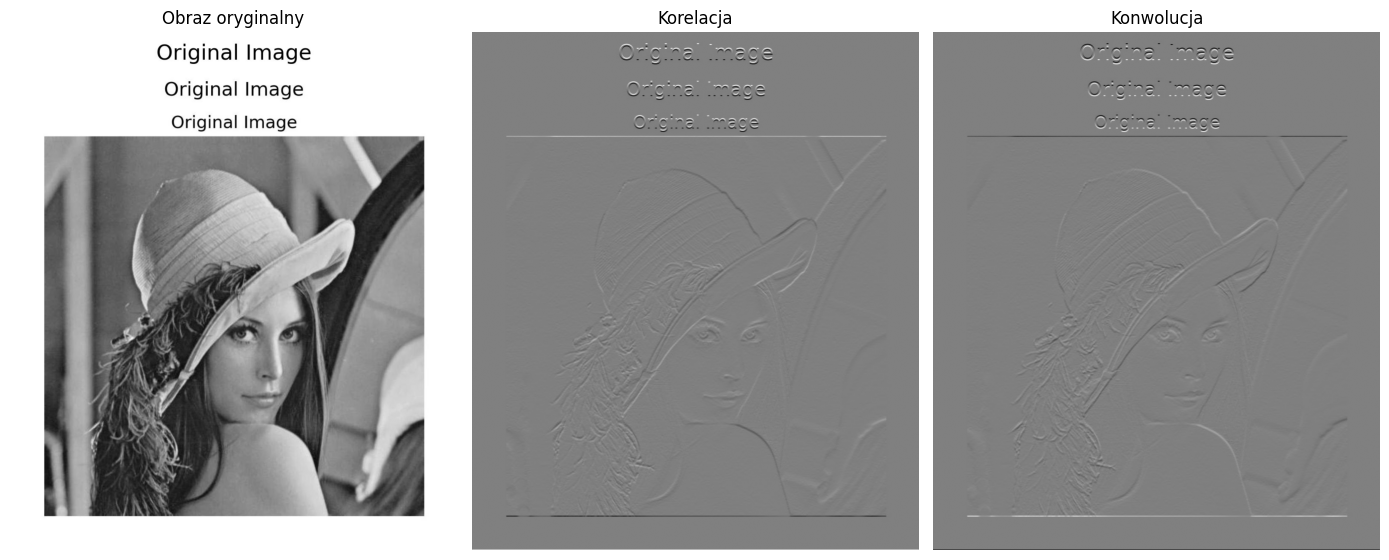

In [6]:
plt.figure(figsize=(14, 6))
plt.subplot(1, 3, 1)
plt.imshow(img_float, cmap="gray", vmin=0, vmax=1)
plt.title("Obraz oryginalny")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(correlation_result, cmap="gray", vmin=-display_limit, vmax=display_limit)
plt.title("Korelacja")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(convolution_result, cmap="gray", vmin=-display_limit, vmax=display_limit)
plt.title("Konwolucja")
plt.axis("off")

plt.tight_layout()
plt.show()

Korelacja i konwolucja w tym wypadku to tylko odwrotność (bielsze -> ciemniejsze). Widać, że poprawnie wykrywają poziome krawędzie (w szczególności "ramke" obrazku)

### 4) załadowanie emoji

In [7]:
def load_emojis(folder_name="emojis"):
    script_dir = globals()['_dh'][0]
    folder_path = os.path.join(script_dir, folder_name)

    emojis = {}
    for filename in sorted(os.listdir(folder_path)):
        if filename.lower().endswith(".png"):
            emoji_name = os.path.splitext(filename)[0]
            emoji_path = os.path.join(folder_path, filename)
            emoji_image = cv2.imread(emoji_path, cv2.IMREAD_UNCHANGED)

            emoji_gray = cv2.cvtColor(
                emoji_image[:, :, :3], cv2.COLOR_BGR2GRAY
            )
            alpha = emoji_image[:, :, 3].astype(np.float32) / 255.0
            

            emoji_gray = emoji_gray.astype(np.float32) / 255.0
            emojis[emoji_name] = (
                emoji_gray * alpha + (1.0 - alpha)
            )

    return emojis

### 5) znormalizowana korelacja

In [8]:
def normalized_correlation(first, second):
    first_centered = first.astype(np.float32) - np.mean(first)
    second_centered = second.astype(np.float32) - np.mean(second)
    denominator = np.sqrt(
        np.sum(first_centered**2) * np.sum(second_centered**2)
    )
    if denominator == 0:
        return 0.0

    return float(np.sum(first_centered * second_centered) / denominator)

### 6) wybranie wzorca i porównanie z resztą

Wybieramy obrazek płaczący śmiejący się i porównujemy z resztą za pomocą powyższej funkcji korelacji. Wynik to od 0 do 1 gdzie 1 to idealnie pokrywający się obrazek.

In [9]:
emojis = load_emojis()

In [10]:
query_name = "1F602"

query_emoji = emojis[query_name]
similarities = {
    name: normalized_correlation(query_emoji, emoji)
    for name, emoji in emojis.items()
    if name != query_name
}

In [11]:
best_match_name = max(similarities, key=similarities.get)
best_match_score = similarities[best_match_name]
print(
    f"Emoji najbardziej podobne do {query_name}: {best_match_name} "
    f"(korelacja: {best_match_score:.3f})"
)

Emoji najbardziej podobne do 1F602: 1F62D (korelacja: 0.671)


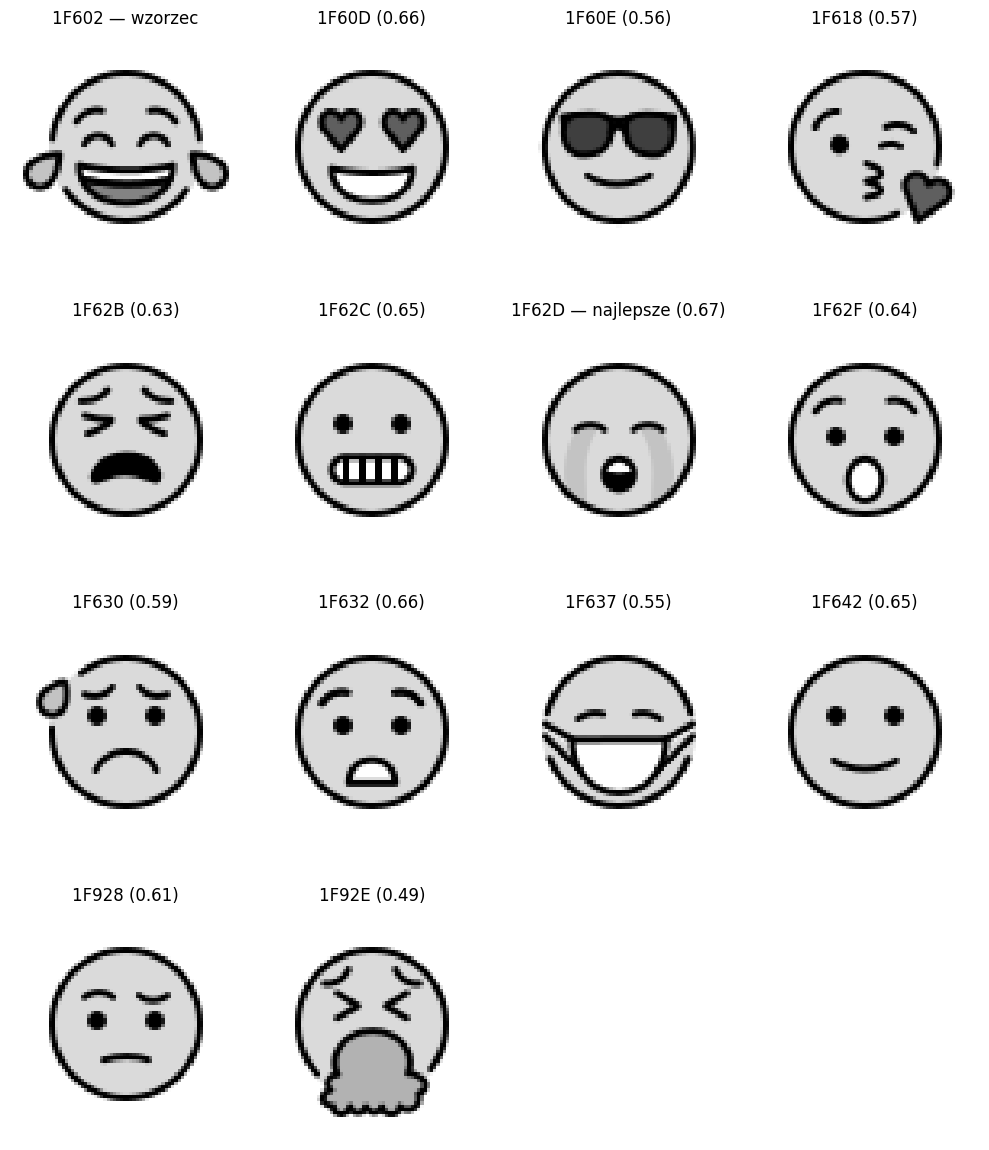

In [12]:
columns = 4
rows = (len(emojis) + columns - 1) // columns
plt.figure(figsize=(10, 3 * rows))

for index, (name, emoji) in enumerate(emojis.items(), start=1):
    plt.subplot(rows, columns, index)
    plt.imshow(emoji, cmap="gray", vmin=0, vmax=1)
    if name == query_name:
        title = f"{name} — wzorzec"
    elif name == best_match_name:
        title = f"{name} — najlepsze ({best_match_score:.2f})"
    else:
        title = f"{name} ({similarities[name]:.2f})"
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

Widać, że wyższy wynik mają emotki z podobnymi elementami (np. identyczne oczy, brwi, zęby), a najmniejszy te którchelementy się najbardziej różnią od query (np trójkątne oczy, obrócone brwi, maska).